# Explainable AI Audit: Credit Default Model

**Problem Statement:** Train a black-box model to predict loan default, then explain it for three audiences who each need something different:

| Stakeholder | Question they ask | Method used |
|---|---|---|
| Regulator | Is the model transparent and non-discriminatory overall? | Feature importance, SHAP (global), fairness/disparate-impact check |
| Loan officer | Why did the model flag *this* applicant? | LIME (local), SHAP (local) |
| Customer | What would I need to change to get approved? | DiCE counterfactuals |

Target `credit_risk`: 1 = good credit (repaid), 0 = bad credit (defaulted). A prediction of 0 means the model recommends rejecting the applicant.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report
)

import shap
import lime
import lime.lime_tabular
import dice_ml

RANDOM_STATE = 42
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

## 1. Data Pipeline

The raw file uses German column codes (`laufkont`, `laufzeit`, ...). We load it, rename every column to its documented English meaning, and keep the original numeric codes for modeling

In [3]:
COLUMN_MAP = {
    "laufkont": "status", 
    "laufzeit": "duration", 
    "moral": "credit_history",
    "verw": "purpose", 
    "hoehe": "amount", 
    "sparkont": "savings",
    "beszeit": "employment_duration", 
    "rate": "installment_rate",
    "famges": "personal_status_sex", 
    "buerge": "other_debtors",
    "wohnzeit": "present_residence", 
    "verm": "property", 
    "alter": "age",
    "weitkred": "other_installment_plans", 
    "wohn": "housing",
    "bishkred": "number_credits", 
    "beruf": "job", 
    "pers": "people_liable",
    "telef": "telephone", 
    "gastarb": "foreign_worker", 
    "kredit": "credit_risk",
}

df = pd.read_csv("SouthGermanCredit.asc", sep=r"\s+", engine="python")
df = df.rename(columns=COLUMN_MAP)
df.head()

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


In [ ]:
# Official code table (Groemping, 2019) used only for our redability
LABELS = {
    "status": {1: "no checking account", 2: "<0 DM", 3: "0-200 DM", 4: ">=200 DM / salary 1yr+"},
    "credit_history": {0: "delay in paying past", 1: "critical/other credits elsewhere",
                        2: "no credits / paid duly", 3: "existing credits paid duly",
                        4: "all credits at bank paid duly"},
    "purpose": {0: "other", 1: "car (new)", 2: "car (used)", 3: "furniture/equipment",
                4: "radio/TV", 5: "domestic appliances", 6: "repairs", 7: "education",
                8: "vacation", 9: "retraining", 10: "business"},
    "savings": {1: "unknown/none", 2: "<100 DM", 3: "100-500 DM", 4: "500-1000 DM", 5: ">=1000 DM"},
    "employment_duration": {1: "unemployed", 2: "<1 yr", 3: "1-4 yrs", 4: "4-7 yrs", 5: ">=7 yrs"},
    "installment_rate": {1: ">=35% of income", 2: "25-35%", 3: "20-25%", 4: "<20%"},
    "personal_status_sex": {1: "male: divorced/separated", 2: "female: non-single or male: single",
                             3: "male: married/widowed", 4: "female: single"},
    "other_debtors": {1: "none", 2: "co-applicant", 3: "guarantor"},
    "present_residence": {1: "<1 yr", 2: "1-4 yrs", 3: "4-7 yrs", 4: ">=7 yrs"},
    "property": {1: "unknown/none", 2: "car or other", 3: "building society/life insurance", 4: "real estate"},
    "other_installment_plans": {1: "bank", 2: "stores", 3: "none"},
    "housing": {1: "for free", 2: "rent", 3: "own"},
    "number_credits": {1: "1", 2: "2-3", 3: "4-5", 4: ">=6"},
    "job": {1: "unemployed/unskilled non-resident", 2: "unskilled resident",
            3: "skilled employee/official", 4: "manager/self-employed/highly qualified"},
    "people_liable": {1: "3 or more", 2: "0 to 2"},
    "telephone": {1: "no", 2: "yes"},
    "foreign_worker": {1: "yes", 2: "no"},
    "credit_risk": {0: "bad", 1: "good"},
}

def labeled(frame):
    out = frame.copy()
    for col, mapping in LABELS.items():
        if col in out.columns:
            out[col] = out[col].map(mapping)
    return out

df_readable = labeled(df)
df_readable.head(3)

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,no checking account,18,all credits at bank paid duly,car (used),1049,unknown/none,<1 yr,<20%,female: non-single or male: single,none,...,car or other,21,none,for free,1,skilled employee/official,0 to 2,no,no,good
1,no checking account,9,all credits at bank paid duly,other,2799,unknown/none,1-4 yrs,25-35%,male: married/widowed,none,...,unknown/none,36,none,for free,2-3,skilled employee/official,3 or more,no,no,good
2,<0 DM,12,no credits / paid duly,retraining,841,<100 DM,4-7 yrs,25-35%,female: non-single or male: single,none,...,unknown/none,23,none,for free,1,unskilled resident,0 to 2,no,no,good


## 2. Exploratory Data Analysis

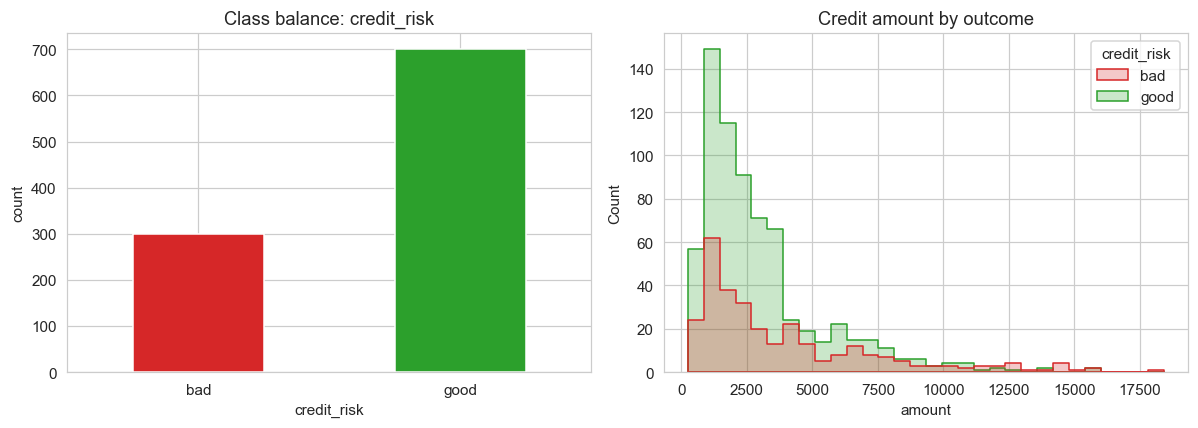

In [7]:
outcome_palette = {"bad": "#d62728", "good": "#2ca02c"}
df_plot = df.copy()
df_plot["credit_risk"] = df_plot["credit_risk"].map(LABELS["credit_risk"])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

df_plot["credit_risk"].value_counts().reindex(["bad", "good"]).plot(
    kind="bar", ax=ax[0], color=[outcome_palette["bad"], outcome_palette["good"]]
)
ax[0].set_title("Class balance: credit_risk")
ax[0].set_xticklabels(["bad", "good"], rotation=0)
ax[0].set_ylabel("count")

sns.histplot(data=df_plot, x="amount", hue="credit_risk", hue_order=["bad", "good"],
             bins=30, ax=ax[1], palette=outcome_palette, element="step")
ax[1].set_title("Credit amount by outcome")

plt.tight_layout()
plt.savefig("figs/01_class_balance_amount.png")
plt.show()

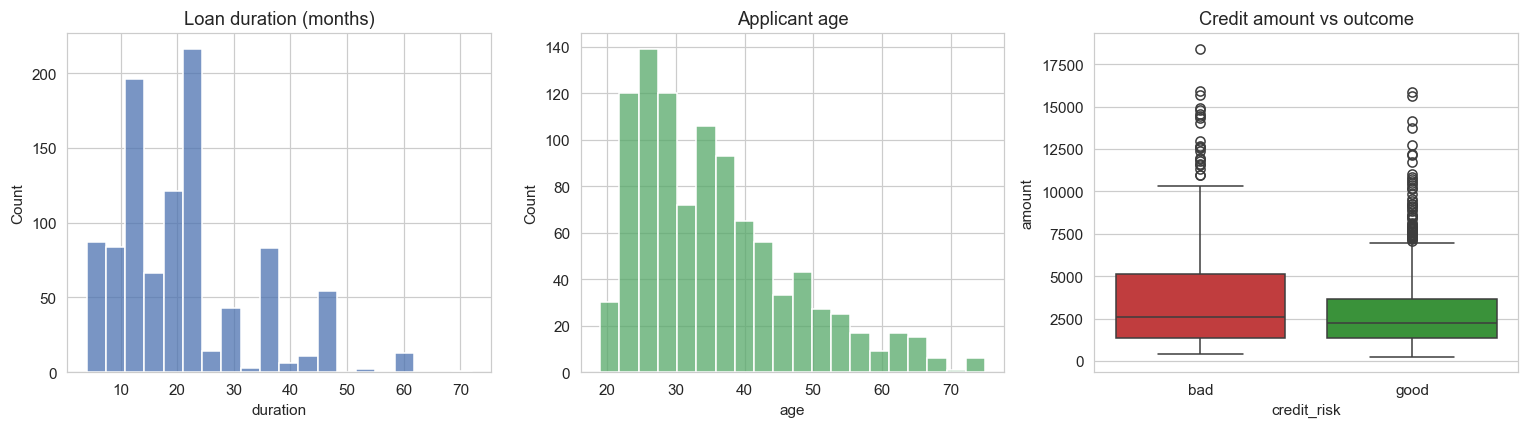

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(df["duration"], bins=20, ax=ax[0], color="#4c72b0")
ax[0].set_title("Loan duration (months)")
sns.histplot(df["age"], bins=20, ax=ax[1], color="#55a868")
ax[1].set_title("Applicant age")
sns.boxplot(data=df, x="credit_risk", y="amount", ax=ax[2], palette=["#d62728", "#2ca02c"])
ax[2].set_xticklabels(["bad", "good"])
ax[2].set_title("Credit amount vs outcome")
plt.tight_layout()
plt.savefig("figs/02_numeric_eda.png")
plt.show()

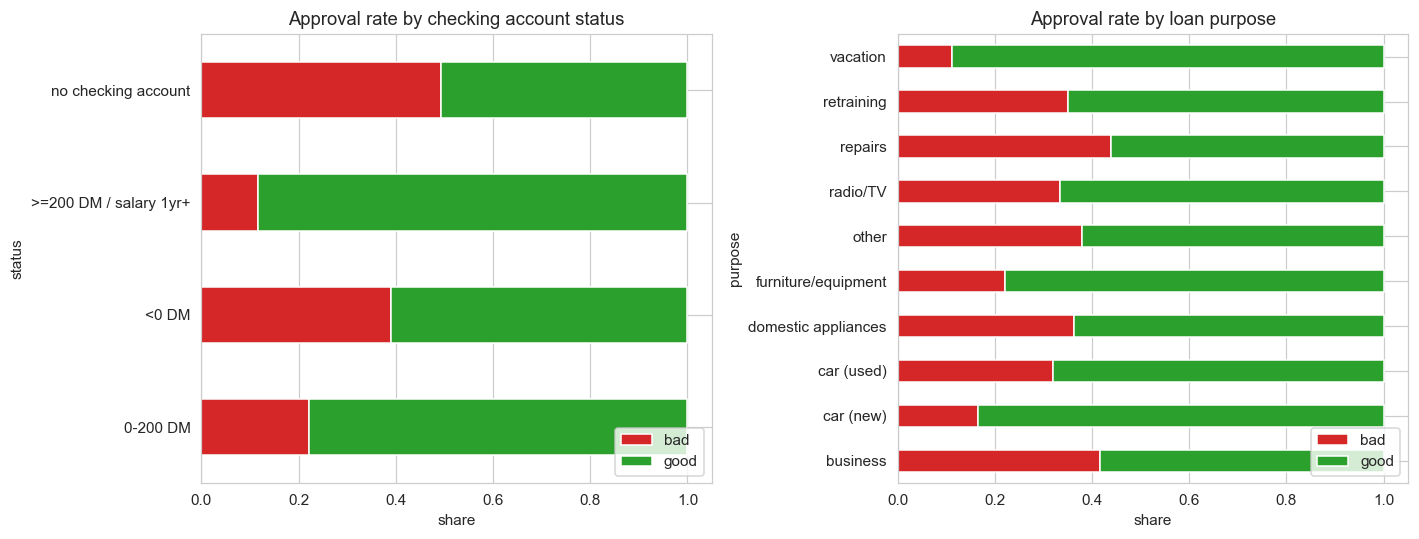

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ct = pd.crosstab(df_readable["status"], df_readable["credit_risk"], normalize="index")
ct.plot(kind="barh", stacked=True, ax=ax[0], color=["#d62728", "#2ca02c"])
ax[0].set_title("Approval rate by checking account status")
ax[0].set_xlabel("share")
ax[0].legend(["bad", "good"], loc="lower right")

ct2 = pd.crosstab(df_readable["purpose"], df_readable["credit_risk"], normalize="index")
ct2.plot(kind="barh", stacked=True, ax=ax[1], color=["#d62728", "#2ca02c"])
ax[1].set_title("Approval rate by loan purpose")
ax[1].set_xlabel("share")
ax[1].legend(["bad", "good"], loc="lower right")

plt.tight_layout()
plt.savefig("figs/03_categorical_eda.png")
plt.show()

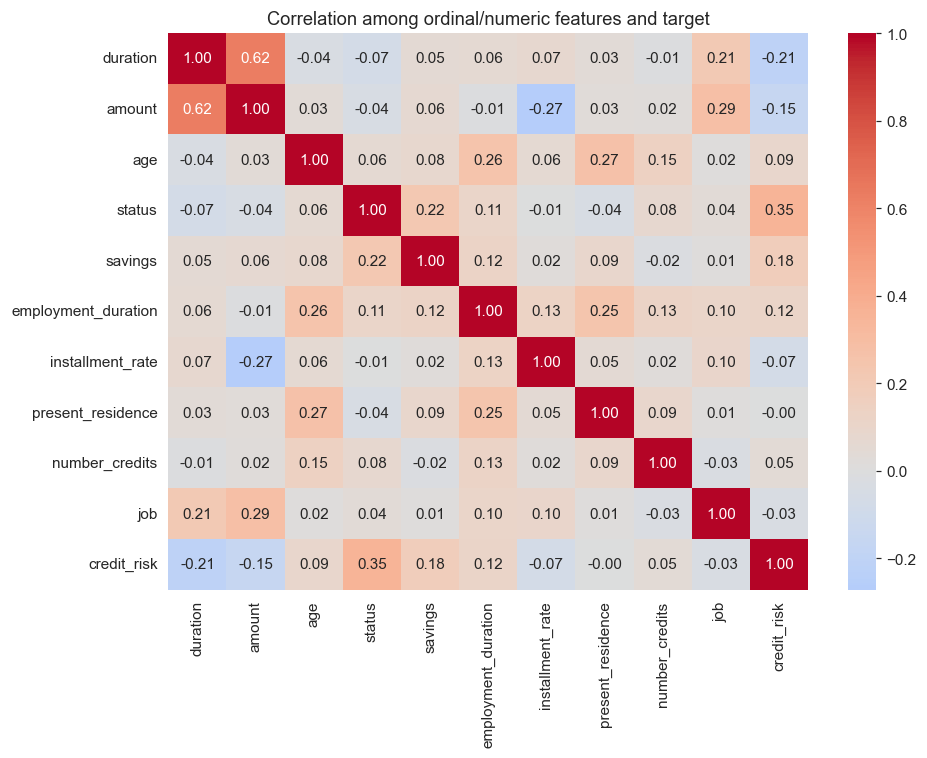

In [10]:
numeric_cols = ["duration", "amount", "age", "status", "savings", "employment_duration",
                 "installment_rate", "present_residence", "number_credits", "job"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols + ["credit_risk"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation among ordinal/numeric features and target")
plt.tight_layout()
plt.savefig("figs/04_correlation.png")
plt.show()

**Notes** 
- the classes are imbalanced (700 good / 300 bad)
- accuracy alone will be misleading and ROC-AUC / recall on the bad class matter more
- Checking-account status increases monotonically with approval rate which is the expected direction (more funds in the account, lower risk)

## 3. Preprocessing and Train/Test Split

Nominal features (no natural order) are one-hot encoded

Ordinal and numeric features are already coded as integers, so they pass through unchanged 

Preprocessing is fit only inside the pipeline

In [11]:
NOMINAL = ["credit_history", "purpose", "personal_status_sex", "other_debtors",
           "property", "other_installment_plans", "housing"]
ORDINAL_NUMERIC = ["duration", "amount", "status", "savings", "employment_duration",
                    "installment_rate", "present_residence", "number_credits",
                    "job", "people_liable", "telephone", "foreign_worker", "age"]

X = df.drop(columns=["credit_risk"])
y = df["credit_risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer(
    transformers=[
        ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL),
        ("ordinal_numeric", "passthrough", ORDINAL_NUMERIC),
    ]
)

print(f"train: {X_train.shape}, test: {X_test.shape}")

train: (800, 20), test: (200, 20)


## 4. Training the Black-Box Models

Both Random Forest and Gradient Boosting are tuned with `RandomizedSearchCV`

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE)),
])
rf_param_dist = {
    "clf__n_estimators": [100, 200, 300, 400, 500],
    "clf__max_depth": [None, 4, 6, 8, 10, 12],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2", None],
}
rf_search = RandomizedSearchCV(
    rf_pipeline, rf_param_dist, n_iter=30, cv=cv, scoring="roc_auc",
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_search.fit(X_train, y_train)
rf_model = rf_search.best_estimator_
print("Random Forest best CV ROC-AUC:", round(rf_search.best_score_, 4))
print("Random Forest best params:", rf_search.best_params_)

Random Forest best CV ROC-AUC: 0.7814
Random Forest best params: {'clf__n_estimators': 500, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 4, 'clf__max_features': 'sqrt', 'clf__max_depth': None}


In [13]:
gbm_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE)),
])
gbm_param_dist = {
    "clf__n_estimators": [100, 150, 200, 300],
    "clf__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "clf__max_depth": [2, 3, 4, 5],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__subsample": [0.7, 0.85, 1.0],
}
gbm_search = RandomizedSearchCV(
    gbm_pipeline, gbm_param_dist, n_iter=30, cv=cv, scoring="roc_auc",
    random_state=RANDOM_STATE, n_jobs=-1
)
gbm_search.fit(X_train, y_train)
gbm_model = gbm_search.best_estimator_
print("Gradient Boosting best CV ROC-AUC:", round(gbm_search.best_score_, 4))
print("Gradient Boosting best params:", gbm_search.best_params_)

Gradient Boosting best CV ROC-AUC: 0.7773
Gradient Boosting best params: {'clf__subsample': 0.7, 'clf__n_estimators': 200, 'clf__min_samples_leaf': 2, 'clf__max_depth': 3, 'clf__learning_rate': 0.03}


## 5. Evaluation

In [14]:
def evaluate(model, name):
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    }

results = pd.DataFrame([evaluate(rf_model, "Random Forest"), evaluate(gbm_model, "Gradient Boosting")])
results.set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Random Forest,0.78,0.782,0.950,0.858,0.829
Gradient Boosting,0.80,0.825,0.907,0.864,0.838


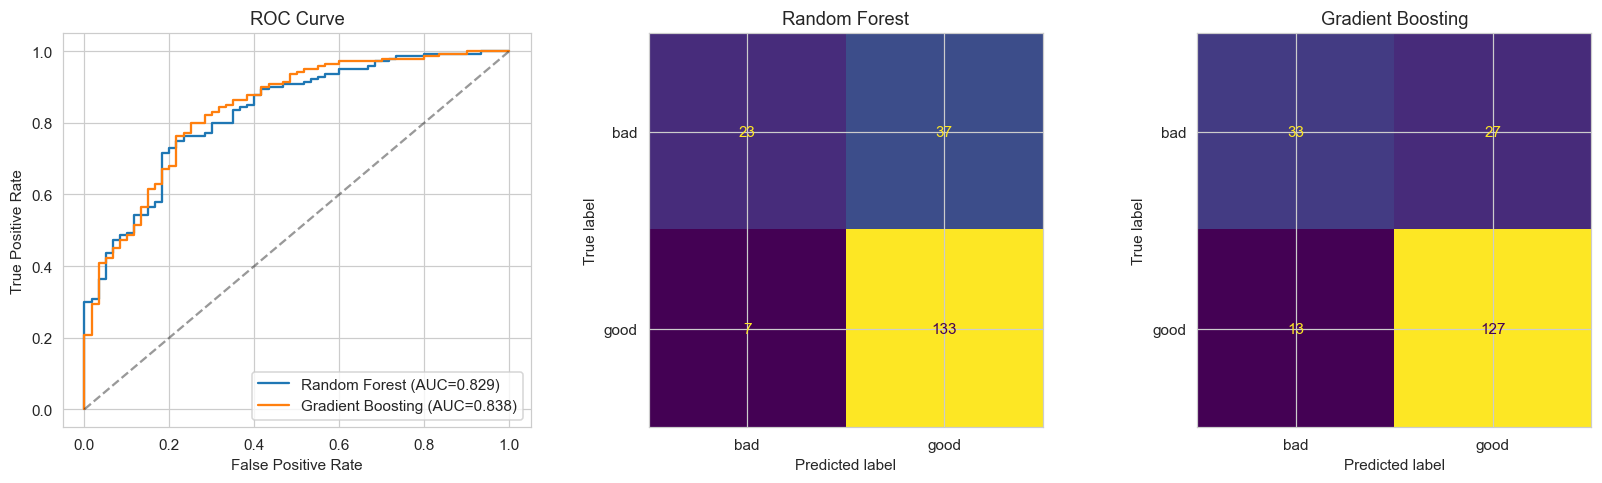

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for model, name, color in [(rf_model, "Random Forest", "#1f77b4"), (gbm_model, "Gradient Boosting", "#ff7f0e")]:
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.3f})", color=color)
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, ax=axes[1], colorbar=False, display_labels=["bad", "good"])
axes[1].set_title("Random Forest")
ConfusionMatrixDisplay.from_estimator(gbm_model, X_test, y_test, ax=axes[2], colorbar=False, display_labels=["bad", "good"])
axes[2].set_title("Gradient Boosting")

plt.tight_layout()
plt.savefig("figs/05_eval.png")
plt.show()

## 6. Calibration Check

For a lending model, the predicted probability itself often gets used downstream (risk-based pricing, reserve calculations), so it should be reasonably calibrated, not just rank-ordered correctly. This matters to a regulator as much as raw accuracy.

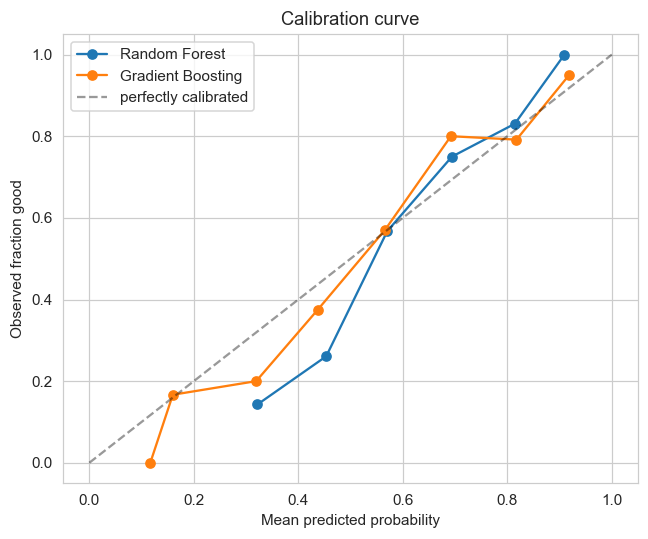

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
for model, name, color in [(rf_model, "Random Forest", "#1f77b4"), (gbm_model, "Gradient Boosting", "#ff7f0e")]:
    frac_pos, mean_pred = calibration_curve(y_test, model.predict_proba(X_test)[:, 1], n_bins=8)
    ax.plot(mean_pred, frac_pos, marker="o", label=name, color=color)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="perfectly calibrated")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed fraction good")
ax.set_title("Calibration curve")
ax.legend()
plt.tight_layout()
plt.savefig("figs/06_calibration.png")
plt.show()

## 7. Built-in Feature Importance

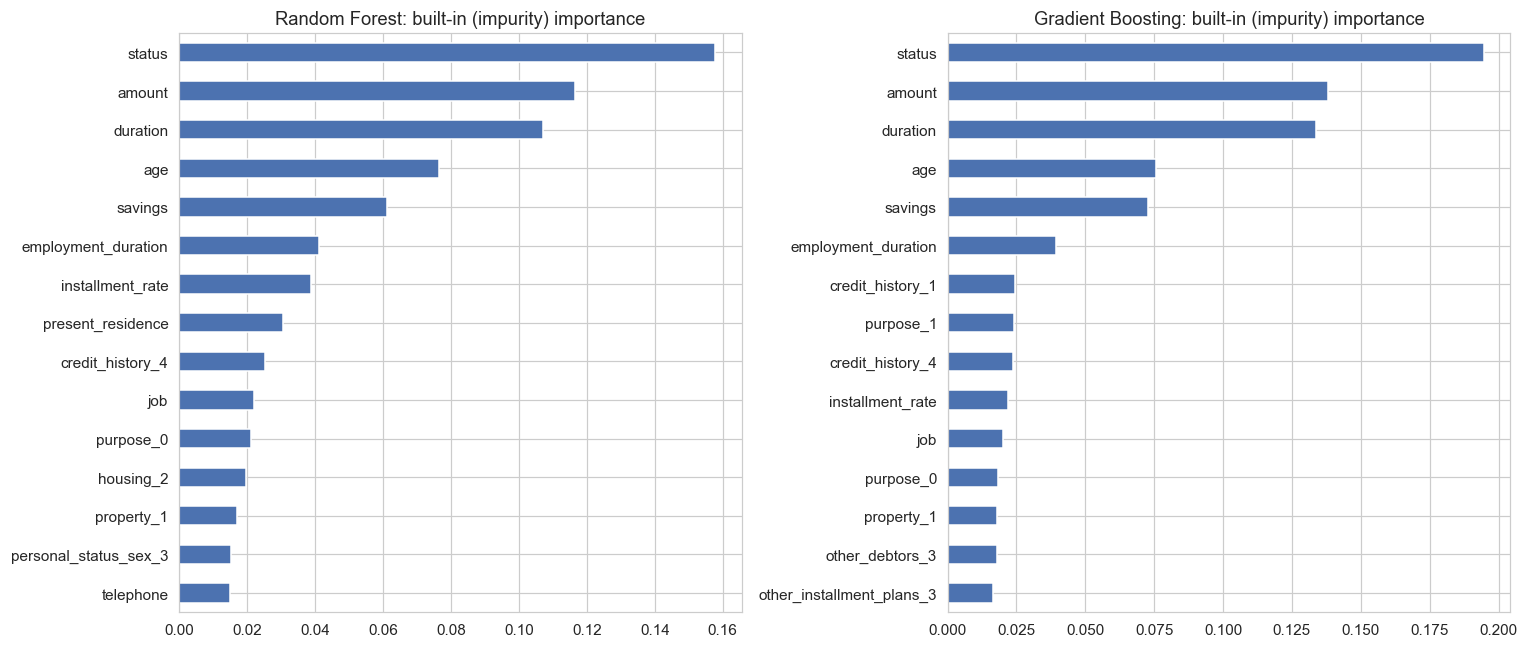

In [17]:
feature_names = rf_model.named_steps["prep"].get_feature_names_out()
feature_names = [f.replace("nominal__", "").replace("ordinal_numeric__", "") for f in feature_names]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, model, name in [(axes[0], rf_model, "Random Forest"), (axes[1], gbm_model, "Gradient Boosting")]:
    importances = pd.Series(model.named_steps["clf"].feature_importances_, index=feature_names)
    importances.sort_values().tail(15).plot(kind="barh", ax=ax, color="#4c72b0")
    ax.set_title(f"{name}: built-in (impurity) importance")
plt.tight_layout()
plt.savefig("figs/07_builtin_importance.png")
plt.show()

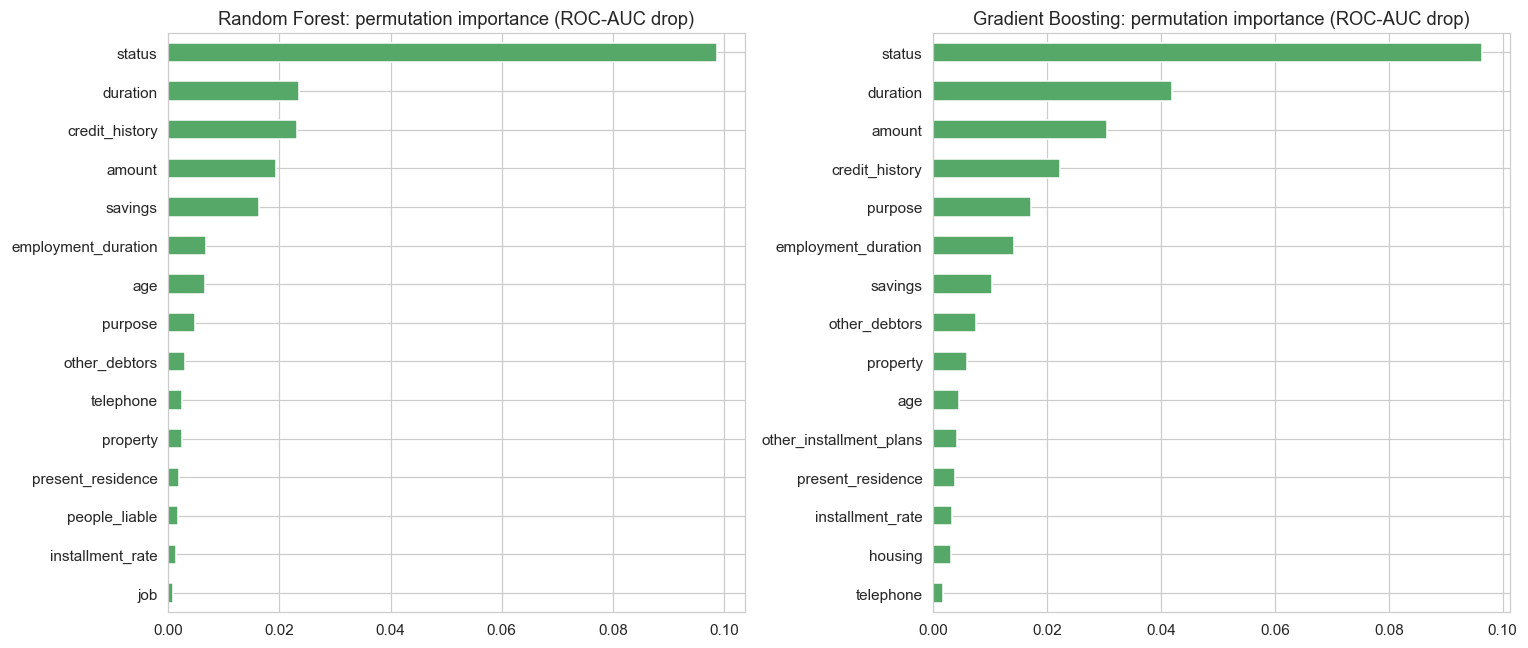

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, model, name in [(axes[0], rf_model, "Random Forest"), (axes[1], gbm_model, "Gradient Boosting")]:
    perm = permutation_importance(model, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1)
    perm_series = pd.Series(perm.importances_mean, index=X_test.columns)
    perm_series.sort_values().tail(15).plot(kind="barh", ax=ax, color="#55a868")
    ax.set_title(f"{name}: permutation importance (ROC-AUC drop)")
plt.tight_layout()
plt.savefig("figs/08_permutation_importance.png")
plt.show()

## 8. Perspective 1: The Regulator

A regulator does not care about one applican

They need to know, globally: which features drive the model, does that match irl lending logic, and is the model discriminating against a particular style or type of group

SHAP's global summary answers the first two questions; an impact check answers the third

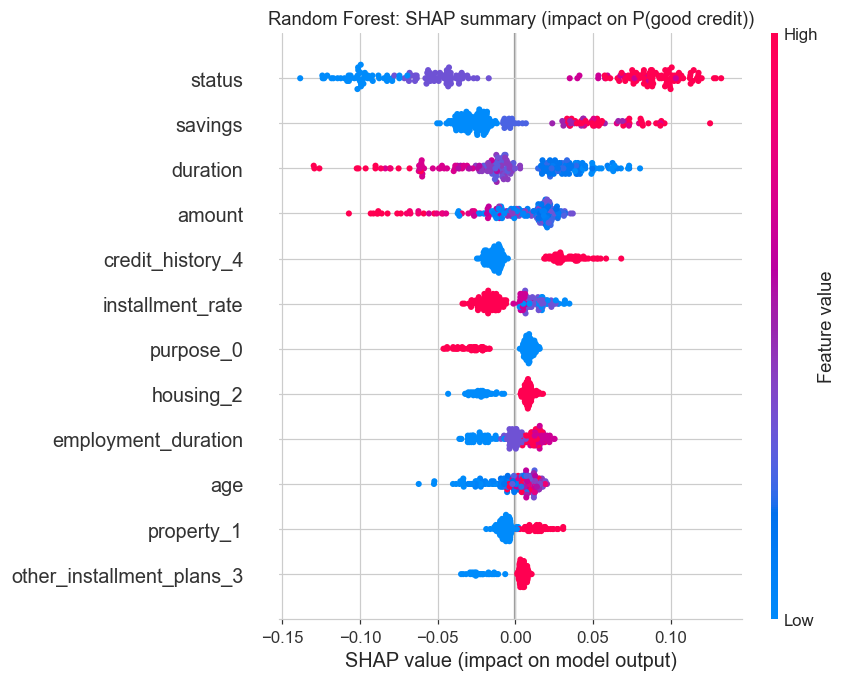

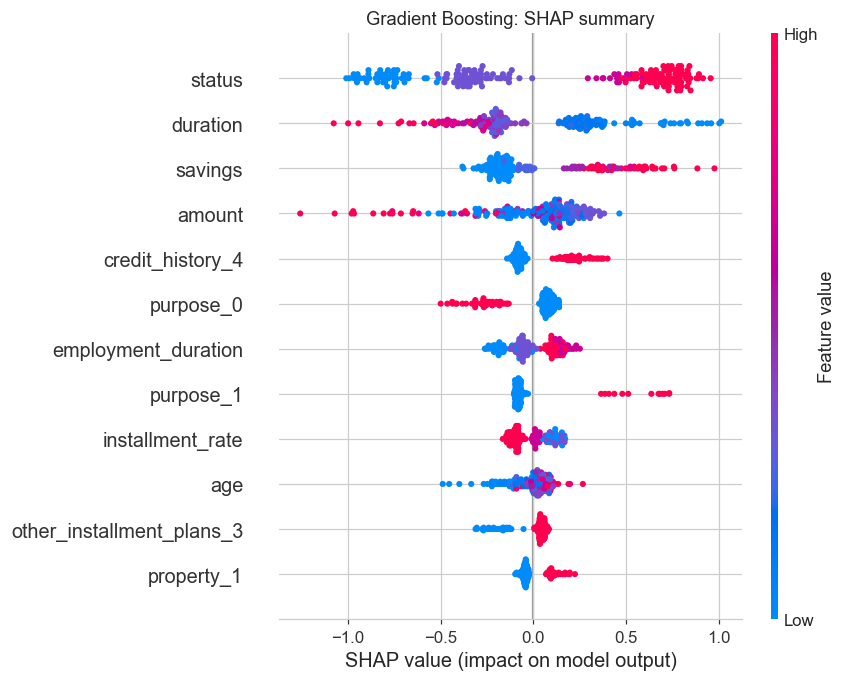

In [19]:
prep = rf_model.named_steps["prep"]
rf_clf = rf_model.named_steps["clf"]
gbm_clf = gbm_model.named_steps["clf"]
X_test_enc = prep.transform(X_test)
X_test_enc_df = pd.DataFrame(X_test_enc, columns=feature_names, index=X_test.index)

def positive_class_shap(explainer, data):
    """Reduce a multi-class Explanation to the 'good credit' (class 1) slice, if needed."""
    exp = explainer(data)
    if exp.values.ndim == 3:
        exp = shap.Explanation(values=exp.values[..., 1], base_values=exp.base_values[..., 1],
                                data=exp.data, feature_names=exp.feature_names)
    return exp

rf_shap = positive_class_shap(shap.TreeExplainer(rf_clf), X_test_enc_df)
gbm_shap = positive_class_shap(shap.TreeExplainer(gbm_clf), X_test_enc_df)

plt.figure()
shap.summary_plot(rf_shap, X_test_enc_df, show=False, max_display=12)
plt.title("Random Forest: SHAP summary (impact on P(good credit))")
plt.tight_layout()
plt.savefig("figs/09_shap_summary_rf.png", bbox_inches="tight")
plt.show()

plt.figure()
shap.summary_plot(gbm_shap, X_test_enc_df, show=False, max_display=12)
plt.title("Gradient Boosting: SHAP summary")
plt.tight_layout()
plt.savefig("figs/09_shap_summary_gbm.png", bbox_inches="tight")
plt.show()

Both models agree on the top drivers: checking-account status, savings, duration and amount dominate, in the expected direction (more funds and shorter/smaller loans push toward "good") Agreement between two differently built and techniques black boxes is itself evidence the pattern is real and not an artifact of one algorithm.

<Figure size 704x528 with 0 Axes>

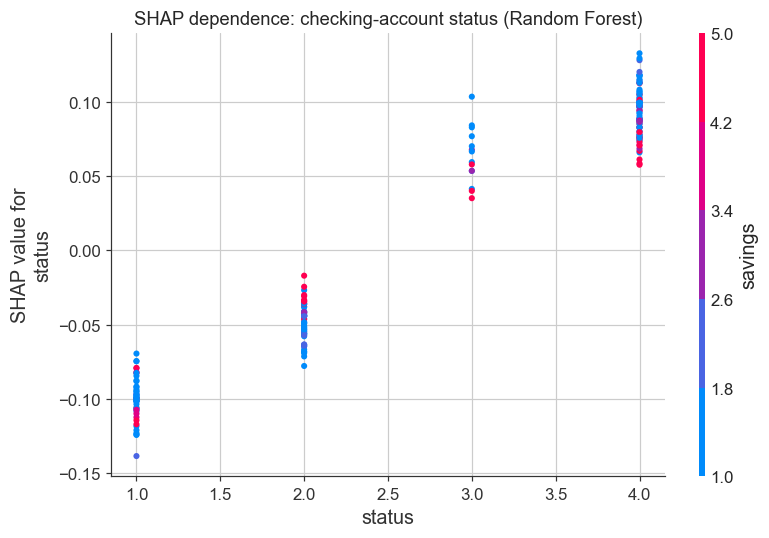

In [20]:
plt.figure()
shap.dependence_plot("status", rf_shap.values, X_test_enc_df, show=False)
plt.title("SHAP dependence: checking-account status (Random Forest)")
plt.tight_layout()
plt.savefig("figs/10_shap_dependence_status.png", bbox_inches="tight")
plt.show()

### Fairness / disparate-impact check

GDPR and ECOA both require lenders to show a model isn't unfairly disadvantaging a protected group. This dataset carries `foreign_worker` (a national-origin proxy) and `age`. We check the four-fifths (80%) rule: the approval rate for the disadvantaged group should be at least 80% of the advantaged group's rate.

In [21]:
def disparate_impact(model, X, group_col, group_labels):
    preds = model.predict(X)
    out = pd.DataFrame({group_col: X[group_col].map(group_labels).values, "approved": preds})
    rates = out.groupby(group_col)["approved"].mean()
    ratio = rates.min() / rates.max()
    return rates, ratio

for model, name in [(rf_model, "Random Forest"), (gbm_model, "Gradient Boosting")]:
    fw_rates, fw_ratio = disparate_impact(model, X_test, "foreign_worker", {1: "foreign worker", 2: "not foreign worker"})
    print(f"--- {name} ---")
    print("Approval rate by foreign_worker:\n", fw_rates.round(3))
    print("Disparate impact ratio:", round(fw_ratio, 3), "-> PASSES 80% rule" if fw_ratio >= 0.8 else "-> FAILS 80% rule")

    age_band = X_test["age"].apply(lambda a: "age<25" if a < 25 else "age>=25")
    age_rates = pd.Series(model.predict(X_test), index=X_test.index).groupby(age_band).mean()
    age_ratio = age_rates.min() / age_rates.max()
    print("Approval rate by age band:\n", age_rates.round(3))
    print("Disparate impact ratio:", round(age_ratio, 3), "-> PASSES 80% rule" if age_ratio >= 0.8 else "-> FAILS 80% rule")
    print()

--- Random Forest ---
Approval rate by foreign_worker:
 foreign_worker
foreign worker        0.800
not foreign worker    0.851
Name: approved, dtype: float64
Disparate impact ratio: 0.94 -> PASSES 80% rule
Approval rate by age band:
 age
age<25     0.654
age>=25    0.879
dtype: float64
Disparate impact ratio: 0.744 -> FAILS 80% rule

--- Gradient Boosting ---
Approval rate by foreign_worker:
 foreign_worker
foreign worker        0.600
not foreign worker    0.774
Name: approved, dtype: float64
Disparate impact ratio: 0.775 -> FAILS 80% rule
Approval rate by age band:
 age
age<25     0.50
age>=25    0.81
dtype: float64
Disparate impact ratio: 0.617 -> FAILS 80% rule



`foreign_worker` passes the four:fifth rule. 

`age` does not: applicants under 25 are approved noticeably less often.. but this does not automatically mean illegal discrimination, since young ppl genuinely correlates with legitimate risk factors the model also sees (shorter `employment_duration`, fewer `number_credits`, less `present_residence` time)

## 9. Perspective 2: The Loan Officer

A loan officer reviews one file at a time and needs a fast, intuitive answer: why did the model score *this* applicant this way

LIME fits a simple local surrogate around a single prediction, which is quick to compute and easy to read

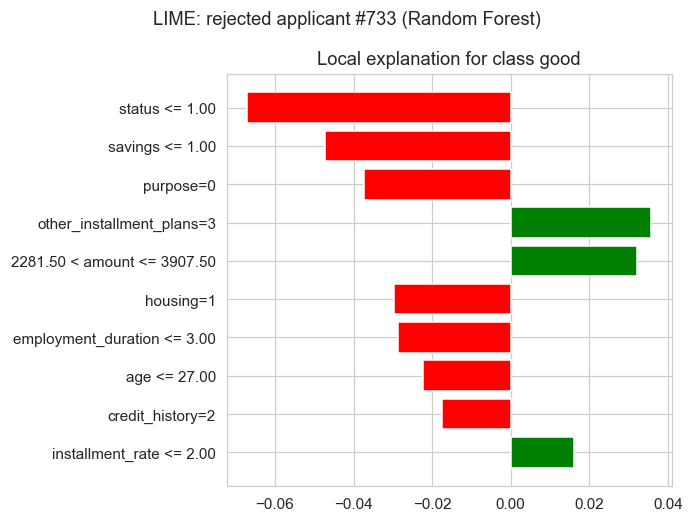

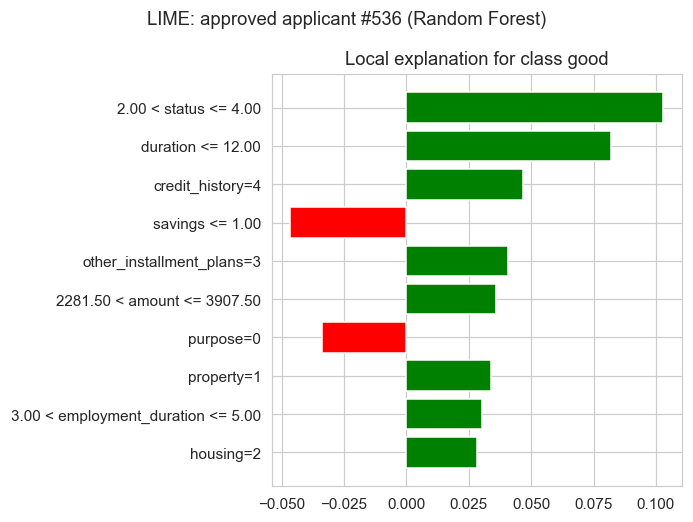

In [22]:
cat_idx = [X_train.columns.get_loc(c) for c in NOMINAL]

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["bad", "good"],
    categorical_features=cat_idx,
    mode="classification",
    random_state=RANDOM_STATE,
)

def rf_predict_fn(arr):
    d = pd.DataFrame(arr, columns=X_train.columns)
    for c in X_train.columns:
        d[c] = d[c].astype(X_train[c].dtype)
    return rf_model.predict_proba(d)

test_preds = rf_model.predict(X_test)
rejected_idx = X_test.index[test_preds == 0][0]
approved_idx = X_test.index[test_preds == 1][0]

exp_rejected = lime_explainer.explain_instance(X_test.loc[rejected_idx].values, rf_predict_fn, num_features=10)
fig = exp_rejected.as_pyplot_figure()
fig.suptitle(f"LIME: rejected applicant #{rejected_idx} (Random Forest)")
plt.tight_layout()
plt.savefig("figs/12_lime_rejected.png", bbox_inches="tight")
plt.show()

exp_approved = lime_explainer.explain_instance(X_test.loc[approved_idx].values, rf_predict_fn, num_features=10)
fig2 = exp_approved.as_pyplot_figure()
fig2.suptitle(f"LIME: approved applicant #{approved_idx} (Random Forest)")
plt.tight_layout()
plt.savefig("figs/13_lime_approved.png", bbox_inches="tight")
plt.show()

### Cross-check against SHAP for the same applicant

LIME and SHAP use different mechanics (local linear regression vs. game theory shap values)

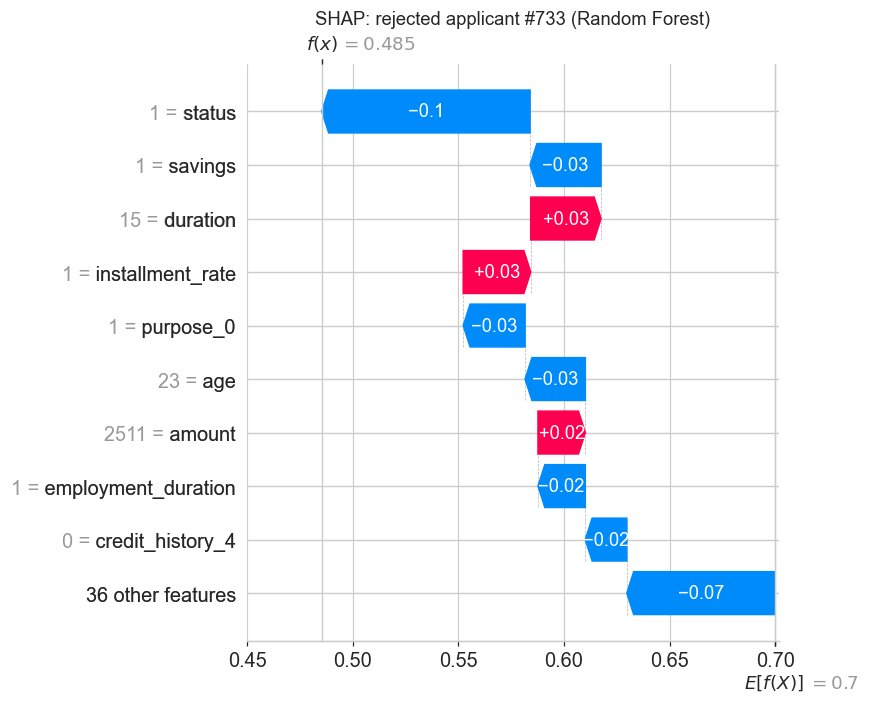

Rejected applicant raw record:
                                                        733
status                                  no checking account
duration                                                 15
credit_history                       no credits / paid duly
purpose                                               other
amount                                                 2511
savings                                        unknown/none
employment_duration                              unemployed
installment_rate                            >=35% of income
personal_status_sex      female: non-single or male: single
other_debtors                                          none
present_residence                                   >=7 yrs
property                    building society/life insurance
age                                                      23
other_installment_plans                                none
housing                                            for free
number_cr

In [23]:
rejected_pos = X_test.index.get_loc(rejected_idx)
plt.figure()
shap.plots.waterfall(rf_shap[rejected_pos], show=False, max_display=10)
plt.title(f"SHAP: rejected applicant #{rejected_idx} (Random Forest)")
plt.tight_layout()
plt.savefig("figs/14_shap_waterfall_rejected.png", bbox_inches="tight")
plt.show()

print("Rejected applicant raw record:")
print(labeled(X_test.loc[[rejected_idx]]).T)

## 10. Perspective 3: The Customer

A rejected customer has a right to know what would change the decision

DiCE searches for the smallest realistic changes to the applicant's *own* record that flip the prediction

I exclude `age`, `personal_status_sex`, `foreign_worker`, `people_liable`, `telephone`, `job`, `employment_duration` and `credit_history` from the search

In [ ]:
train_for_dice = X_train.copy()
train_for_dice["credit_risk"] = y_train.values

dice_data = dice_ml.Data(
    dataframe=train_for_dice,
    continuous_features=["duration", "amount", "age"],
    outcome_name="credit_risk",
)
dice_model = dice_ml.Model(model=rf_model, backend="sklearn")
dice_explainer = dice_ml.Dice(dice_data, dice_model, method="genetic")

features_to_vary = ["status", "duration", "amount", "savings", "other_debtors", "property",
                     "other_installment_plans", "housing", "number_credits", "present_residence", "purpose"]

test_proba = pd.Series(rf_model.predict_proba(X_test)[:, 1], index=X_test.index)
rejected_near_boundary = test_proba[rf_model.predict(X_test) == 0].sort_values(ascending=False).index[0]
customer_query = X_test.loc[[rejected_near_boundary]]

counterfactuals = dice_explainer.generate_counterfactuals(
    customer_query, total_CFs=3, desired_class="opposite", features_to_vary=features_to_vary
)
cf_df = counterfactuals.cf_examples_list[0].final_cfs_df.drop(columns=["credit_risk"])
print(f"Applicant #{rejected_near_boundary}, model score P(good) = {test_proba[rejected_near_boundary]:.3f}")
labeled(cf_df)

100%|██████████| 1/1 [00:40<00:00, 40.23s/it]

Applicant #758, model score P(good) = 0.497


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker
0,<0 DM,30,no credits / paid duly,other,2181,>=1000 DM,1-4 yrs,<20%,female: non-single or male: single,none,>=7 yrs,unknown/none,24,none,rent,2-3,skilled employee/official,0 to 2,no,no
0,<0 DM,4,no credits / paid duly,other,250,unknown/none,1-4 yrs,<20%,female: non-single or male: single,guarantor,1-4 yrs,real estate,24,bank,rent,1,skilled employee/official,0 to 2,no,no


In [25]:
original = customer_query.iloc[0]
print("Suggested changes to flip this applicant from rejected to approved:\n")
for cf_id, row in cf_df.reset_index(drop=True).iterrows():
    changes = {c: (original[c], row[c]) for c in original.index if original[c] != row[c]}
    print(f"Option {cf_id + 1}:")
    for feat, (old, new) in changes.items():
        old_label = LABELS.get(feat, {}).get(old, old)
        new_label = LABELS.get(feat, {}).get(new, new)
        print(f"   {feat}: {old_label}  ->  {new_label}")
    print()

Suggested changes to flip this applicant from rejected to approved:

Option 1:
   amount: 2150  ->  2181
   savings: unknown/none  ->  >=1000 DM
   other_debtors: guarantor  ->  none
   present_residence: 1-4 yrs  ->  >=7 yrs
   property: real estate  ->  unknown/none
   other_installment_plans: bank  ->  none
   number_credits: 1  ->  2-3

Option 2:
   duration: 30  ->  4
   amount: 2150  ->  250



## Conclusion

The three stakeholders needed different things from the same two models, and no single explanation method would have covered all three:

- **Regulator** wanted proof the model behaves sensibly overall and does not discriminate. Global SHAP plus a four-fifths disparate-impact check
- **Loan officer** wanted a per-case reason. LIME gave that in seconds, and cross-checking it against SHAP for the same applicant gives a concrete answer that its correct
- **Customer** wanted a path forward, not just a rejection. So using DICE we can aid them

Random Forest and Gradient Boosting scored almost identically and agreed on which features matter